In [52]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
import os
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage


import psycopg
from psycopg.rows import dict_row
from langgraph.checkpoint.postgres import PostgresSaver
from dotenv import load_dotenv

load_dotenv()  # Load environment variables from .env file


True

In [53]:
def get_database_url():
    database_url = os.getenv("DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DATABASE_URL is missing. Please add your Render PostgreSQL External Database URL to .env"
        )

    if "sslmode=" not in database_url:
        separator = "&" if "?" in database_url else "?"
        database_url = f"{database_url}{separator}sslmode=require"

    return database_url

In [54]:
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
if not OPENAI_API_KEY:
    raise ValueError("OPENAI_API_KEY is missing. Please add it to your .env file.")

In [55]:
class Task(BaseModel):
    id : int
    title: str
    brief: str = Field(..., description="A brief description of the task")

In [56]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [57]:
class State(TypedDict):
    topic : str
    plan  : Plan
    #results from worker agent get concatenated automatically
    sections: Annotated[List[str],operator.add]
    final : str

In [58]:
llm = ChatOpenAI(
    model="gpt-6.1-terra",
    use_responses_api=True,
    reasoning={"effort": "none"},
    temperature=0.5,
    max_tokens=4000,
    max_retries=2
)

In [59]:
def orchestator(state: State) ->dict:
    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(content=("Create a blog plan with 5-7 sections based on the given topic.")),
            HumanMessage(content=f"Topic: {state['topic']}")
        ]
    )
    return {"plan": plan}

In [60]:
def fanout(state:State):

    return [Send("worker",{"task": task, "topic":state["topic"], "plan":state["plan"]}) for task in state["plan"].tasks]

In [61]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [ ]:
from pathlib import Path

from pathlib import Path

def reducer(state: State) -> dict:
    
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    # ---- save to file ----
    filename = title.lower().replace(" ", "_") + ".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}

In [63]:
graph_builder = StateGraph(State)

# Add nodes
graph_builder.add_node("orchestrator", orchestator)
graph_builder.add_node("worker", worker)
graph_builder.add_node("reducer", reducer)

# Define graph flow
graph_builder.add_edge(START, "orchestrator")

# Dynamic fan-out to worker nodes
graph_builder.add_conditional_edges("orchestrator", fanout, ["worker"])

# Workers send results to reducer
graph_builder.add_edge("worker", "reducer")

# Finish
graph_builder.add_edge("reducer", END)


In [64]:
DATABASE_URL = get_database_url()
_conn = psycopg.connect(DATABASE_URL, autocommit=True, row_factory=dict_row)

checkpointer = PostgresSaver(_conn)
checkpointer.setup()

In [65]:
app = graph_builder.compile(checkpointer=checkpointer)

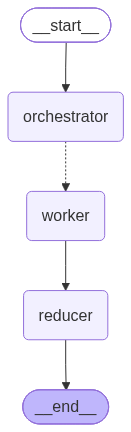

In [66]:
app

In [67]:
config = {
        "configurable": {
            "thread_id": "test_thread_id"
        }
    }

In [68]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []}, config=config)

AttributeError: 'list' object has no attribute 'strip'